# 10 — 2026-10-25: Qwen2.5-Omni-7B vs InternVL2.5-8B

Experiments 06 and 08 (same questions, conditions, prompts, frames and option orders) and their explanation codes
(07, 09). No model needed. Outputs: `outputs/2026-10-25_compare_models/`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, mannwhitneyu

ROOT = Path.cwd().parent
EXP_DIR = ROOT / "outputs/2026-10-25_compare_models"
FIGURES = EXP_DIR / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
MODELS = {"Qwen": ("2026-10-18_full_shuffled", "2026-10-19_code_explanations"),
          "InternVL": ("2026-10-25_internvl_full", "2026-10-25_code_explanations_internvl")}
CONDITIONS = ["Q_noE", "Q", "T", "T_told", "VT", "VTmis"]
WITH_E = CONDITIONS[1:]
CODES = ["cites_dialogue", "cites_visual", "says_insufficient", "names_missing_visual", "notices_mismatch"]
HIGH_CONFIDENCE = 0.8
ABCD = ["prob_A", "prob_B", "prob_C", "prob_D"]

keys = pd.read_parquet(ROOT / "data-private/processed/answer_keys.parquet")[["question_id", "correct_answer_key"]]


def load(results, coding):
    df = pd.read_json(ROOT / "outputs" / results / "results.jsonl", lines=True).drop_duplicates(["question_id", "condition"])
    df = df.merge(keys, on="question_id")
    df["abstain"] = df.answer == "E"
    df["p_E"] = df.prob_E.fillna(0)
    df["correct"] = df.answer == df.correct_answer_key
    df["confidence"] = df[ABCD].max(axis=1) / df[ABCD].sum(axis=1)
    df["confidently_wrong"] = ~df.correct & ~df.abstain & (df.confidence >= HIGH_CONFIDENCE)
    df["forced_correct"] = df[ABCD].idxmax(axis=1).str[-1] == df.correct_answer_key
    df["claims_video"] = df.evidence_answer.isin(["video", "both"])
    labels = pd.read_json(ROOT / "outputs" / coding / "judge_labels.jsonl", lines=True, dtype={"prompt_sha": str})
    both = labels.groupby("key")[CODES].all()
    df["key"] = df.question_id + "|" + df.condition
    return df.merge(both, left_on="key", right_index=True, how="left")


data = {name: load(*paths) for name, paths in MODELS.items()}
for name, df in data.items():
    print(name, df.question_id.nunique(), "questions,", len(df), "rows,", df[CODES[0]].isna().sum(), "without codes")

Qwen 598 questions, 3588 rows, 0 without codes
InternVL 598 questions, 3588 rows, 0 without codes


## Behavior

In [2]:
summary = pd.concat({name: df.groupby("condition").agg(
    abstain=("abstain", "mean"),
    mean_p_E=("p_E", "mean"),
    accuracy=("correct", "mean"),
    best_abcd_right=("forced_correct", "mean"),
    confidently_wrong=("confidently_wrong", "mean"),
).reindex(CONDITIONS) for name, df in data.items()}, axis=1)
summary.to_csv(EXP_DIR / "summary.csv")
(summary * 100).round(1)

Qwen                                                      \
          abstain mean_p_E accuracy best_abcd_right confidently_wrong   
condition                                                               
Q_noE         0.0      0.0     43.6            44.1              16.6   
Q            61.7     54.1     19.4            45.3               9.0   
T            47.5     44.6     32.1            54.7              12.0   
T_told       61.9     56.5     25.3            55.2               8.0   
VT           29.4     30.1     42.0            56.2              13.9   
VTmis        41.6     39.4     32.6            52.5              15.1   

          InternVL                                                      
           abstain mean_p_E accuracy best_abcd_right confidently_wrong  
condition                                                               
Q_noE          0.0      0.0     44.3            44.5              15.2  
Q             58.7     50.3     18.9            43.0               9.2  
T             42.0     41.0     32.4            51.2              10.5  
T_told        53.8     49.5     29.1            52.7               7.7  
VT            13.7     16.9     49.0            56.4              14.0  
VTmis         15.7     19.7     42.1            49.0              13.9

In [3]:
for name, df in data.items():
    print(f"===== {name}")
    abstained = df.pivot(index="question_id", columns="condition", values="abstain")
    for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
        start = int((~abstained[a] & abstained[b]).sum())
        stop = int((abstained[a] & ~abstained[b]).sum())
        print(f"abstain {a} -> {b}: {start} start, {stop} stop; exact McNemar p = {binomtest(start, start + stop).pvalue:.2g}")
    right = df.pivot(index="question_id", columns="condition", values="forced_correct")
    for a, b in [("Q", "T"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
        gain = int((~right[a] & right[b]).sum())
        loss = int((right[a] & ~right[b]).sum())
        print(f"best A-D right {a} -> {b}: {gain} gained, {loss} lost; exact McNemar p = {binomtest(gain, gain + loss).pvalue:.2g}")
    pE = df.pivot(index="question_id", columns="condition", values="p_E")
    answers = df.pivot(index="question_id", columns="condition", values="answer")
    video_mattered = answers["VT"] != answers["T"]
    rise = pE["T_told"] - pE["T"]
    print(f"P(E) rise T -> T_told: video mattered {rise[video_mattered].mean():+.3f} (n = {video_mattered.sum()}), "
          f"did not {rise[~video_mattered].mean():+.3f} (n = {(~video_mattered).sum()}); "
          f"Mann-Whitney p = {mannwhitneyu(rise[video_mattered], rise[~video_mattered]).pvalue:.2g}")

===== Qwen
abstain Q -> T: 39 start, 124 stop; exact McNemar p = 1.6e-11
abstain T -> T_told: 87 start, 1 stop; exact McNemar p = 5.8e-25
abstain T -> VT: 19 start, 127 stop; exact McNemar p = 8.4e-21
abstain VT -> VTmis: 101 start, 28 stop; exact McNemar p = 7e-11
abstain T -> VTmis: 47 start, 82 stop; exact McNemar p = 0.0026
best A-D right Q -> T: 109 gained, 53 lost; exact McNemar p = 1.3e-05
best A-D right T -> VT: 54 gained, 45 lost; exact McNemar p = 0.42
best A-D right VT -> VTmis: 42 gained, 64 lost; exact McNemar p = 0.041
best A-D right T -> VTmis: 48 gained, 61 lost; exact McNemar p = 0.25
P(E) rise T -> T_told: video mattered +0.137 (n = 185), did not +0.111 (n = 413); Mann-Whitney p = 0.00018
===== InternVL
abstain Q -> T: 64 start, 164 stop; exact McNemar p = 2.7e-11
abstain T -> T_told: 72 start, 1 stop; exact McNemar p = 1.6e-20
abstain T -> VT: 14 start, 183 stop; exact McNemar p = 1e-38
abstain VT -> VTmis: 47 start, 35 stop; exact McNemar p = 0.22
abstain T -> VTmis

In [4]:
abstained = pd.concat({name: df.pivot(index="question_id", columns="condition", values="abstain")
                       for name, df in data.items()}, axis=1)
pd.DataFrame({"both abstain": (abstained["Qwen"] & abstained["InternVL"]).mean(),
              "same decision": (abstained["Qwen"] == abstained["InternVL"]).mean()}).reindex(WITH_E).round(3)

,both abstain,same decision
condition,,
Q,0.472,0.739
T,0.308,0.721
T_told,0.453,0.749
VT,0.090,0.749
VTmis,0.117,0.661


## Self-report

In [5]:
evidence = pd.concat({name: pd.crosstab(df.condition, df.evidence_answer, normalize="index")
                      .reindex(index=CONDITIONS, columns=["nothing", "transcript", "video", "both"], fill_value=0)
                      for name, df in data.items()}, axis=1)
evidence.to_csv(EXP_DIR / "evidence_question.csv")
(evidence * 100).round(1)

Qwen                       InternVL                       
evidence_answer nothing transcript video both  nothing transcript video  both
condition                                                                    
Q_noE              55.0       35.8   3.8  5.4     74.9       11.4   7.4   6.4
Q                  78.4       18.7   1.7  1.2     94.1        4.5   0.3   1.0
T                   9.9       89.6   0.3  0.2     22.1       77.3   0.2   0.5
T_told             14.9       85.1   0.0  0.0     24.7       75.3   0.0   0.0
VT                  8.9       84.6   1.8  4.7     31.4        5.9  15.4  47.3
VTmis              19.2       78.4   0.7  1.7     44.0        8.0  10.5  37.5

In [6]:
codes = pd.concat({name: df.groupby("condition")[CODES].mean().reindex(CONDITIONS)
                   for name, df in data.items()}, axis=1)
codes.to_csv(EXP_DIR / "codes_by_condition.csv")
(codes * 100).round(1).T

condition                      Q_noE     Q     T  T_told    VT  VTmis
Qwen     cites_dialogue          0.5   0.2  46.7    63.2  20.9   21.1
         cites_visual            6.9   1.5   2.2     2.2  16.4   15.2
         says_insufficient       0.0  51.8  29.1    47.3  14.2   17.4
         names_missing_visual    0.0   2.0   1.5     7.9   2.0    1.3
         notices_mismatch        0.0   0.0   0.0     0.0   0.0    0.0
InternVL cites_dialogue          3.2   2.0  69.7    76.6  24.2   27.4
         cites_visual           13.5   4.0   3.0     2.7  34.4   24.1
         says_insufficient       0.5  58.5  43.0    54.3  13.9   16.9
         names_missing_visual    0.0   2.7   1.5     3.7   4.0    5.2
         notices_mismatch        0.0   0.0   0.0     0.0   0.2    0.0

In [7]:
for name, df in data.items():
    told = df[df.condition == "T_told"]
    mentions_video = told.explanation.str.contains(r"\bvideo", case=False).mean()
    audio = df[df.explanation.str.contains(r"\baudio", case=False)].condition.value_counts().to_dict()
    visual = df.pivot(index="question_id", columns="condition", values="cites_visual")
    print(f"{name}: T_told explanations mentioning the video {mentions_video:.1%}; 'audio' by condition {audio}; "
          f"cites things seen in both VT and VTmis {(visual.VT & visual.VTmis).sum()}, only in VTmis {(~visual.VT & visual.VTmis).sum()}")

Qwen: T_told explanations mentioning the video 7.5%; 'audio' by condition {'Q_noE': 14, 'T': 7, 'Q': 6, 'VTmis': 2, 'VT': 1}; cites things seen in both VT and VTmis 29, only in VTmis 62
InternVL: T_told explanations mentioning the video 2.7%; 'audio' by condition {'T_told': 5}; cites things seen in both VT and VTmis 98, only in VTmis 46


## Figures

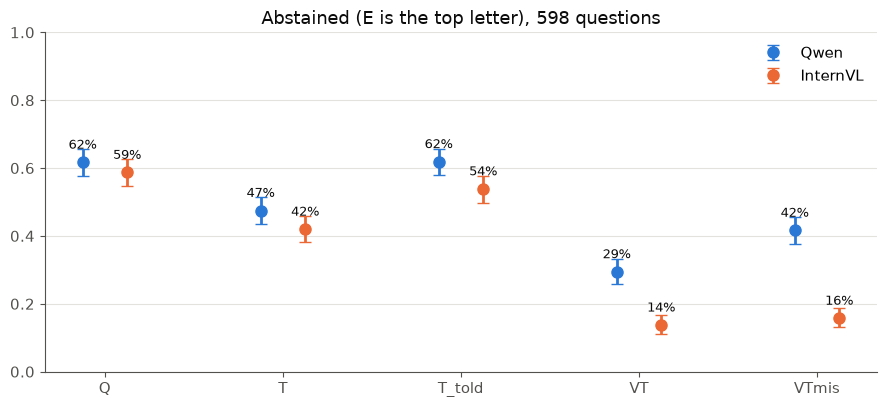

In [8]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e2dc"
COLORS = {"Qwen": BLUE, "InternVL": ORANGE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "font.size": 11, "legend.frameon": False})


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * (p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5 / (1 + z**2 / n)
    return centre - half, centre + half


def dodge_plot(ax, column, conditions, title):
    for k, (name, df) in enumerate(data.items()):
        x = np.arange(len(conditions)) + (k - 0.5) * 0.25
        g = df.groupby("condition")[column]
        value = g.mean().reindex(conditions)
        lo, hi = zip(*[wilson(g.sum()[c], g.size()[c]) for c in conditions])
        ax.errorbar(x, value, yerr=[value - lo, np.array(hi) - value], fmt="o", ms=8, color=COLORS[name], capsize=4,
                    lw=2, label=name)
        for xi, v in zip(x, value):
            ax.text(xi, v + 0.04, f"{v:.0%}", ha="center", color=INK, fontsize=9)
    ax.set(xticks=range(len(conditions)), xticklabels=conditions, ylim=(0, 1), title=title)


fig, ax = plt.subplots(figsize=(9, 4.2))
dodge_plot(ax, "abstain", WITH_E, "Abstained (E is the top letter), 598 questions")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_by_model.png", dpi=200)
plt.show()

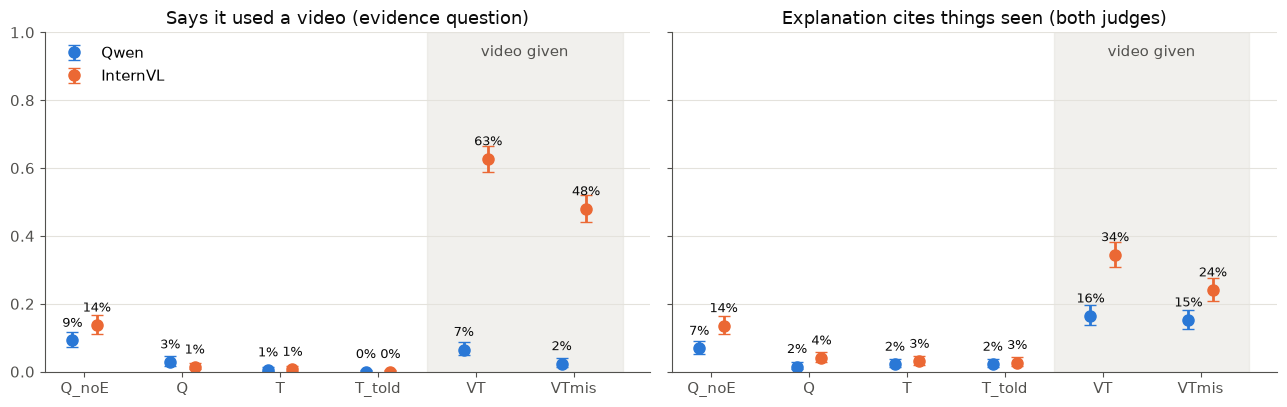

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
dodge_plot(axes[0], "claims_video", CONDITIONS, "Says it used a video (evidence question)")
dodge_plot(axes[1], "cites_visual", CONDITIONS, "Explanation cites things seen (both judges)")
for ax in axes:
    ax.axvspan(3.5, 5.5, color=GRID, alpha=0.5, zorder=0)
    ax.text(4.5, 0.93, "video given", ha="center", color=MUTED)
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "video_self_report_by_model.png", dpi=200)
plt.show()